Ca_external (target, no faults) = 1.183500e-05 F
N (parallel per section) = 9, Su (sections in series) = 5
Pt (branches in parallel) = 1, S (series units per branch) = 3
C_lines (no faults) = [5.9175e-05 5.9175e-05 5.9175e-05 5.9175e-05 5.9175e-05]
C_total (no faults) = 1.1835e-05

===== TABLE: opened vs capacitances, voltages and currents =====
        opened | Ca_internal (uF) |  Ca_phase (uF) |     Vunit1 (V) |     Vunit2 (V) |     Vunit3 (V) |       |Va| (V) |       |Vb| (V) |       |Vc| (V) |      |V_N| (V) |       |Ia| (A) |       |Ib| (A) |       |Ic| (A)
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
             0 |      11.835000 |       3.945000 |        7501.52 |        7501.52 |        7501.52 |       19918.58 |       19918.58 |       19918.58 |           0.00 |          33.47 |          33.47 |       

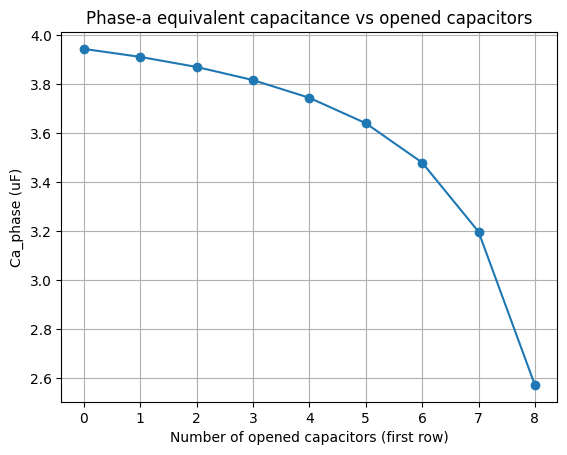

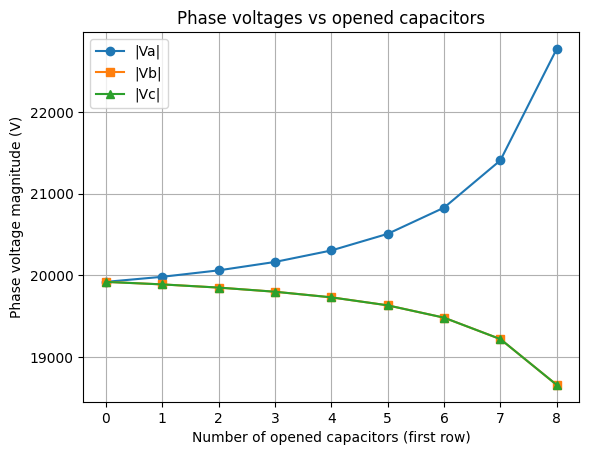

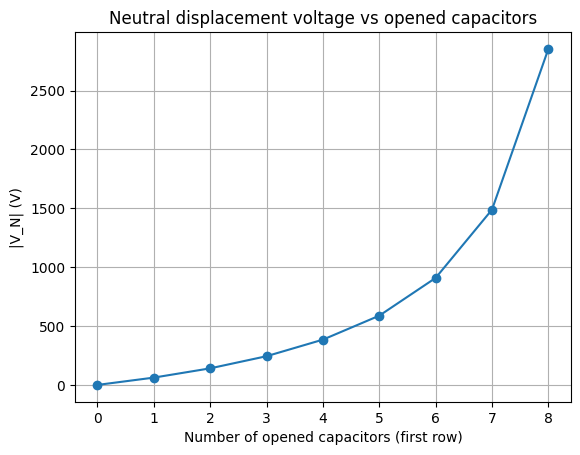

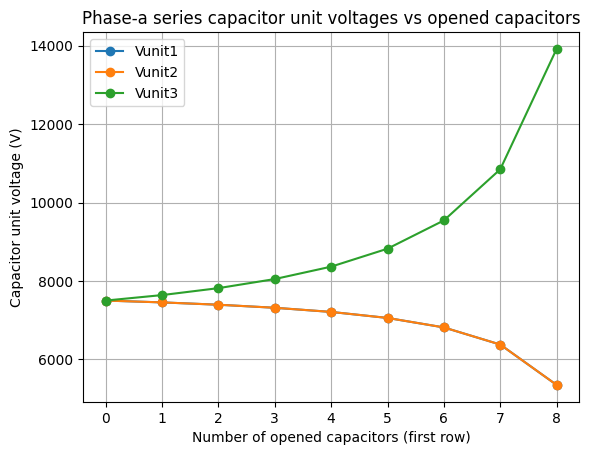

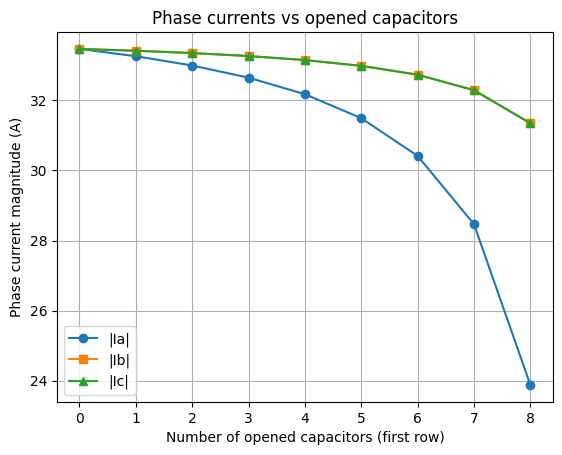

In [83]:
import numpy as np
import matplotlib.pyplot as plt
# Funciona apenas com unidades capacitivas ("latas") em série
pi = np.pi


class ThreePhaseRLC:
    """Three-phase RLC circuit connected in star with isolated neutral."""

    def __init__(self, R, L, Cb, freq_hz, V_ll):
        """Store circuit parameters that are common to all operating points."""
        self.R = R
        self.L = L
        self.Cb = Cb
        self.freq_hz = freq_hz
        self.V_ll = V_ll
        self.omega = 2 * pi * freq_hz
        self.V_phase = V_ll / np.sqrt(3)

        self.VaS = self.phasor(self.V_phase, 0.0)
        self.VbS = self.phasor(self.V_phase, -120.0)
        self.VcS = self.phasor(self.V_phase, 120.0)

    # ---------- basic helpers ----------

    @staticmethod
    def phasor(magnitude, angle_deg):
        """Create a complex phasor from magnitude and angle in degrees."""
        angle_rad = np.deg2rad(angle_deg)
        value = magnitude * np.exp(1j * angle_rad)
        return value

    @staticmethod
    def mag_deg(z):
        """Return magnitude and angle (deg) of a complex number."""
        magnitude = np.abs(z)
        angle = np.rad2deg(np.angle(z))
        return magnitude, angle

    # ---------- capacitor bank helpers (N parallel, Su series) ----------

    @staticmethod
    def design_internal_matrix(C_target, N, Su):
        """
        Design internal capacitor matrix for N parallel, Su in series.
        Condition: C_total(no faults) = C_target.

        For N parallel and Su in series:
            C_total = N * C0 / Su  =>  C0 = C_target * Su / N.
        """
        C0 = C_target * Su / N
        C_matrix = C0 * np.ones((Su, N))
        return C_matrix

    @staticmethod
    def compute_equivalent_capacitance(C_matrix):
        """
        C_matrix: shape (Su, N)
        Topology:
            - Each row: N capacitors in parallel
            - Su rows in series

        Returns:
            C_lines: array with equivalent capacitance of each row (parallel)
            C_total: equivalent capacitance of the whole bank (series of rows)
        """
        C_lines = np.sum(C_matrix, axis=1)

        if np.any(C_lines == 0.0):
            C_total = 0.0
            return C_lines, C_total

        inv_C = 1.0 / C_lines
        inv_sum = np.sum(inv_C)
        C_total = 1.0 / inv_sum

        return C_lines, C_total

    # ---------- RLC solver ----------

    def compute(self, Ca):
        """
        Compute voltages, currents and capacitor voltages
        for a given Ca (phase a capacitance).
        """
        ZaC = 1.0 / (1j * self.omega * Ca)
        ZbC = 1.0 / (1j * self.omega * self.Cb)
        ZcC = 1.0 / (1j * self.omega * self.Cb)

        Za = self.R + 1j * self.omega * self.L + ZaC
        Zb = self.R + 1j * self.omega * self.L + ZbC
        Zc = self.R + 1j * self.omega * self.L + ZcC

        Ya = 1.0 / Za
        Yb = 1.0 / Zb
        Yc = 1.0 / Zc

        VN_num = self.VaS * Ya + self.VbS * Yb + self.VcS * Yc
        VN_den = Ya + Yb + Yc
        VN = VN_num / VN_den

        Va = self.VaS - VN
        Vb = self.VbS - VN
        Vc = self.VcS - VN

        Ia = Va / Za
        Ib = Vb / Zb
        Ic = Vc / Zc

        VaC = Ia * ZaC
        VbC = Ib * ZbC
        VcC = Ic * ZcC

        result = {
            "VN": VN,
            "Va": Va, "Vb": Vb, "Vc": Vc,
            "Ia": Ia, "Ib": Ib, "Ic": Ic,
            "VaC": VaC, "VbC": VbC, "VcC": VcC,
            "Za": Za, "Zb": Zb, "Zc": Zc
        }
        return result

    # ---------- full opening study (no phasors here) ----------

    def run_opening_study(self, Ca_external, N, Su, Pt=1, S=3):
        """
        Study for a capacitor bank connected to phase a.

        Internal bank:
            - N capacitors in parallel per section (row)
            - Su sections in series
            - total equivalent (no faults) = Ca_external

        External connection (per phase):
            - Pt branches in parallel
            - each branch: S series capacitors
                -> (S - 1) units with Ca_external
                -> 1 unit with Ca_internal (degraded bank)

        For each 'opened' = 0..N-1:
            - compute Ca_internal, Ca_phase
            - compute |V_N|, |Va|, |Vb|, |Vc|
            - compute |Ia|, |Ib|, |Ic|
            - compute voltage on each series capacitor unit of phase a
        """
        print(f"Ca_external (target, no faults) = {Ca_external:.6e} F")
        print(f"N (parallel per section) = {N}, Su (sections in series) = {Su}")
        print(f"Pt (branches in parallel) = {Pt}, S (series units per branch) = {S}")

        C_matrix_base = self.design_internal_matrix(Ca_external, N, Su)

        C_lines_0, C_total_0 = self.compute_equivalent_capacitance(C_matrix_base)
        print("C_lines (no faults) =", C_lines_0)
        print("C_total (no faults) =", C_total_0)

        opened_list = []
        Ca_internal_list = []
        Ca_phase_list = []
        VN_mag_list = []
        Va_mag_list = []
        Vb_mag_list = []
        Vc_mag_list = []
        Ia_mag_list = []
        Ib_mag_list = []
        Ic_mag_list = []
        V_units_list = []

        for opened in range(0, N):
            C_matrix = C_matrix_base.copy()
            if opened > 0:
                C_matrix[0, 0:opened] = 0.0

            _, Ca_internal = self.compute_equivalent_capacitance(C_matrix)

            # Series branch: (S - 1) elements with Ca_external and 1 with Ca_internal
            den = (S - 1) * (1.0 / Ca_external) + (1.0 / Ca_internal)
            C_series = 1.0 / den

            # Pt identical branches in parallel
            Ca_phase = Pt * C_series

            data = self.compute(Ca_phase)
            VN_mag = np.abs(data["VN"])
            Va_mag = np.abs(data["Va"])
            Vb_mag = np.abs(data["Vb"])
            Vc_mag = np.abs(data["Vc"])
            Ia_mag = np.abs(data["Ia"])
            Ib_mag = np.abs(data["Ib"])
            Ic_mag = np.abs(data["Ic"])

            # Voltage across equivalent capacitor of phase a
            V_total_cap = np.abs(data["VaC"])

            # Series units: (S-1) with Ca_external, 1 with Ca_internal
            C_units = []
            for _ in range(S - 1):
                C_units.append(Ca_external)
            C_units.append(Ca_internal)
            C_units_array = np.array(C_units)

            # Voltage division in series capacitors: Vk = V_total * (C_series / Ck)
            V_units = V_total_cap * (C_series / C_units_array)

            opened_list.append(opened)
            Ca_internal_list.append(Ca_internal)
            Ca_phase_list.append(Ca_phase)
            VN_mag_list.append(VN_mag)
            Va_mag_list.append(Va_mag)
            Vb_mag_list.append(Vb_mag)
            Vc_mag_list.append(Vc_mag)
            Ia_mag_list.append(Ia_mag)
            Ib_mag_list.append(Ib_mag)
            Ic_mag_list.append(Ic_mag)
            V_units_list.append(V_units)

        opened_array = np.array(opened_list)
        Ca_internal_array = np.array(Ca_internal_list)
        Ca_phase_array = np.array(Ca_phase_list)
        VN_mag_array = np.array(VN_mag_list)
        Va_mag_array = np.array(Va_mag_list)
        Vb_mag_array = np.array(Vb_mag_list)
        Vc_mag_array = np.array(Vc_mag_list)
        Ia_mag_array = np.array(Ia_mag_list)
        Ib_mag_array = np.array(Ib_mag_list)
        Ic_mag_array = np.array(Ic_mag_list)
        V_units_array = np.array(V_units_list)   # shape: (num_opened, S)

        self._print_table(
            opened_array,
            Ca_internal_array,
            Ca_phase_array,
            VN_mag_array,
            Va_mag_array,
            Vb_mag_array,
            Vc_mag_array,
            Ia_mag_array,
            Ib_mag_array,
            Ic_mag_array,
            V_units_array
        )

        self._plot_results(
            opened_array,
            Ca_phase_array,
            VN_mag_array,
            Va_mag_array,
            Vb_mag_array,
            Vc_mag_array,
            Ia_mag_array,
            Ib_mag_array,
            Ic_mag_array,
            V_units_array
        )

    @staticmethod
    def _print_table(
        opened_array,
        Ca_internal_array,
        Ca_phase_array,
        VN_mag_array,
        Va_mag_array,
        Vb_mag_array,
        Vc_mag_array,
        Ia_mag_array,
        Ib_mag_array,
        Ic_mag_array,
        V_units_array
    ):
        """Print results table with capacitances, voltages and currents."""
        num_units = V_units_array.shape[1]

        cols = [
            "opened",
            "Ca_internal (uF)",
            "Ca_phase (uF)"
        ]

        for k in range(num_units):
            label = f"Vunit{k+1} (V)"
            cols.append(label)

        cols.extend([
            "|Va| (V)",
            "|Vb| (V)",
            "|Vc| (V)",
            "|V_N| (V)",
            "|Ia| (A)",
            "|Ib| (A)",
            "|Ic| (A)"
        ])

        header = " | ".join([f"{c:>14s}" for c in cols])
        print("\n===== TABLE: opened vs capacitances, voltages and currents =====")
        print(header)
        print("-" * len(header))

        for idx in range(len(opened_array)):
            values = []

            opened_val = opened_array[idx]
            ci = Ca_internal_array[idx] * 1e6
            cp = Ca_phase_array[idx] * 1e6

            values.append(f"{opened_val:14d}")
            values.append(f"{ci:14.6f}")
            values.append(f"{cp:14.6f}")

            for k in range(num_units):
                v_unit = V_units_array[idx, k]
                values.append(f"{v_unit:14.2f}")

            va = Va_mag_array[idx]
            vb = Vb_mag_array[idx]
            vc = Vc_mag_array[idx]
            vn = VN_mag_array[idx]
            ia = Ia_mag_array[idx]
            ib = Ib_mag_array[idx]
            ic = Ic_mag_array[idx]

            values.append(f"{va:14.2f}")
            values.append(f"{vb:14.2f}")
            values.append(f"{vc:14.2f}")
            values.append(f"{vn:14.2f}")
            values.append(f"{ia:14.2f}")
            values.append(f"{ib:14.2f}")
            values.append(f"{ic:14.2f}")

            line = " | ".join(values)
            print(line)

    @staticmethod
    def _plot_results(
        opened_array,
        Ca_phase_array,
        VN_mag_array,
        Va_mag_array,
        Vb_mag_array,
        Vc_mag_array,
        Ia_mag_array,
        Ib_mag_array,
        Ic_mag_array,
        V_units_array
    ):
        """Plot various quantities versus number of opened capacitors."""

        num_units = V_units_array.shape[1]

        # 1) Ca_phase vs opened
        plt.figure()
        plt.plot(opened_array, Ca_phase_array * 1e6, marker="o")
        plt.xlabel("Number of opened capacitors (first row)")
        plt.ylabel("Ca_phase (uF)")
        plt.title("Phase-a equivalent capacitance vs opened capacitors")
        plt.grid(True)
        plt.show()

        # 2) Phase voltages in the same figure
        plt.figure()
        plt.plot(opened_array, Va_mag_array, marker="o", label="|Va|")
        plt.plot(opened_array, Vb_mag_array, marker="s", label="|Vb|")
        plt.plot(opened_array, Vc_mag_array, marker="^", label="|Vc|")
        plt.xlabel("Number of opened capacitors (first row)")
        plt.ylabel("Phase voltage magnitude (V)")
        plt.title("Phase voltages vs opened capacitors")
        plt.legend()
        plt.grid(True)
        plt.show()

        # 3) Neutral voltage in a separate figure
        plt.figure()
        plt.plot(opened_array, VN_mag_array, marker="o")
        plt.xlabel("Number of opened capacitors (first row)")
        plt.ylabel("|V_N| (V)")
        plt.title("Neutral displacement voltage vs opened capacitors")
        plt.grid(True)
        plt.show()

        # 4) Voltage on each series capacitor unit of phase a
        plt.figure()
        for k in range(num_units):
            plt.plot(
                opened_array,
                V_units_array[:, k],
                marker="o",
                label=f"Vunit{k+1}"
            )
        plt.xlabel("Number of opened capacitors (first row)")
        plt.ylabel("Capacitor unit voltage (V)")
        plt.title("Phase-a series capacitor unit voltages vs opened capacitors")
        plt.legend()
        plt.grid(True)
        plt.show()

        # 5) Phase currents in same figure
        plt.figure()
        plt.plot(opened_array, Ia_mag_array, marker="o", label="|Ia|")
        plt.plot(opened_array, Ib_mag_array, marker="s", label="|Ib|")
        plt.plot(opened_array, Ic_mag_array, marker="^", label="|Ic|")
        plt.xlabel("Number of opened capacitors (first row)")
        plt.ylabel("Phase current magnitude (A)")
        plt.title("Phase currents vs opened capacitors")
        plt.legend()
        plt.grid(True)
        plt.show()

    # ---------- separate phasor plotting for a chosen "opened" ----------

    def plot_phasors_for_opened(self, Ca_external, N, Su, Pt=1, S=3, opened=0):
        """
        Plot voltage and current phasors for a chosen number of opened capacitors
        in the first row.

        opened: integer in [0, N-1]
        """
        if opened < 0 or opened >= N:
            raise ValueError("opened must be between 0 and N-1")

        # Rebuild internal matrix
        C_matrix_base = self.design_internal_matrix(Ca_external, N, Su)
        C_matrix = C_matrix_base.copy()
        if opened > 0:
            C_matrix[0, 0:opened] = 0.0

        _, Ca_internal = self.compute_equivalent_capacitance(C_matrix)

        # Series branch: (S - 1) elements with Ca_external and 1 with Ca_internal
        den = (S - 1) * (1.0 / Ca_external) + (1.0 / Ca_internal)
        C_series = 1.0 / den

        # Pt identical branches in parallel
        Ca_phase = Pt * C_series

        data = self.compute(Ca_phase)

        self._plot_phasor_voltages(
            data["Va"], data["Vb"], data["Vc"], data["VN"], opened
        )
        self._plot_phasor_currents(
            data["Ia"], data["Ib"], data["Ic"], opened
        )

    @staticmethod
    def _plot_phasor_voltages(Va, Vb, Vc, VN, opened_value):
        """
        Plot phasor diagram of phase voltages and neutral displacement.

        Va, Vb, Vc: phase-to-neutral voltages of the load (phasors)
        VN: neutral displacement voltage (load neutral with respect to source neutral/earth)
        """

        def to_xy(z):
            x = np.real(z)
            y = np.imag(z)
            return x, y

        # Neutral displacement (from origin to VN)
        x_n, y_n = to_xy(VN)

        # Phase tip points in absolute coordinates (earth reference):
        # tip_a = VN + Va, etc.
        tip_a = VN + Va
        tip_b = VN + Vb
        tip_c = VN + Vc

        x_a, y_a = to_xy(tip_a)
        x_b, y_b = to_xy(tip_b)
        x_c, y_c = to_xy(tip_c)

        plt.figure()

        # Neutral displacement vector (0 -> VN)
        plt.plot([0.0, x_n], [0.0, y_n], marker="o", linestyle="--", label="V_N")

        # Phase-to-neutral voltages drawn from the neutral point
        plt.plot([x_n, x_a], [y_n, y_a], marker="o", label="Va (phase a)")
        plt.plot([x_n, x_b], [y_n, y_b], marker="o", label="Vb (phase b)")
        plt.plot([x_n, x_c], [y_n, y_c], marker="o", label="Vc (phase c)")

        # Triangle showing line voltages (connect tips of Va, Vb, Vc)
        plt.plot([x_a, x_b], [y_a, y_b])
        plt.plot([x_b, x_c], [y_b, y_c])
        plt.plot([x_c, x_a], [y_c, y_a])

        plt.axhline(0.0)
        plt.axvline(0.0)
        plt.gca().set_aspect("equal", adjustable="box")
        plt.xlabel("Real axis")
        plt.ylabel("Imag axis")
        plt.title(f"Voltage phasors (opened = {opened_value})")
        plt.legend()
        plt.grid(True)
        plt.show()

    @staticmethod
    def _plot_phasor_currents(Ia, Ib, Ic, opened_value):
        """Plot phasor diagram of phase currents."""
        def to_xy(z):
            x = np.real(z)
            y = np.imag(z)
            return x, y

        x_a, y_a = to_xy(Ia)
        x_b, y_b = to_xy(Ib)
        x_c, y_c = to_xy(Ic)

        plt.figure()
        plt.plot([0.0, x_a], [0.0, y_a], marker="o", label="Ia")
        plt.plot([0.0, x_b], [0.0, y_b], marker="o", label="Ib")
        plt.plot([0.0, x_c], [0.0, y_c], marker="o", label="Ic")

        plt.axhline(0.0)
        plt.axvline(0.0)
        plt.gca().set_aspect("equal", adjustable="box")
        plt.xlabel("Real axis")
        plt.ylabel("Imag axis")
        plt.title(f"Current phasors (opened = {opened_value})")
        plt.legend()
        plt.grid(True)
        plt.show()


# ===================== MINIMAL MAIN PROGRAM =====================

if __name__ == "__main__":
    R = 1e-3
    L = 204.949e-3
    Cb = 3.945e-6
    freq_hz = 60.0
    V_ll = 34.5e3

    Ca_external = 3.945e-6 * 3   # base capacitance of each external unit
    N = 9                        # N capacitors in parallel per section (internal bank)
    Su = 5                       # Su sections in series (internal bank)
    Pt = 1                       # parallel branches of series chain
    S = 3                        # series units per branch

    circuit = ThreePhaseRLC(R, L, Cb, freq_hz, V_ll)

    # Run full study: table + scalar plots
    circuit.run_opening_study(Ca_external, N, Su, Pt=Pt, S=S)

    # OPTIONAL: phasor diagrams for a chosen "opened"
    # Choose how many elements are opened in the first row (0..N-1)
    # opened_for_phasor = 4
    # circuit.plot_phasors_for_opened(Ca_external, N, Su, Pt=Pt, S=S, opened=opened_for_phasor)
